# Proyecto Final: Ciencia de Datos en Acción
## Salarios en Ciencia de Datos (2020 - 2022)

**Integrantes:** Juan Barreto, Alejandra (apellido), Diego Gutierrez

**Repositorio:** https://github.com/Diegogv23/proyecto-final-dataxperience

**Dataset:** Data Science Job Salaries (Kaggle, autor ruchi798) - https://www.kaggle.com/datasets/ruchi798/data-science-job-salaries

### ¿Por qué elegimos este dataset?
Elegimos este dataset porque trata un tema real y cercano a nuestra carrera: qué factores (experiencia, tamaño de empresa, trabajo remoto) influyen en el salario de quienes trabajan con datos. Nos ayuda a entender el mercado laboral al que vamos a entrar y nos permite aplicar todo lo visto en el curso, desde la limpieza hasta un modelo predictivo.

### Pregunta que queremos responder
**¿Qué factores influyen más en el salario de un profesional de ciencia de datos?**

### Preguntas por etapa

**Etapa 1: Exploración y limpieza**

1. ¿Qué tan confiables son los datos? ¿Hay nulos, duplicados o variables mal codificadas?
2. ¿Qué variables tenemos y de qué tipo son (numéricas y categóricas)?

**Etapa 2: Estadística descriptiva**

3. ¿Cuál es el salario típico (mediana) y qué tanto varía de una persona a otra?
4. ¿Cuánto más gana un senior que un junior?
5. ¿El tamaño de la empresa se relaciona con el salario?
6. ¿Hay salarios atípicos (outliers)? ¿A qué cargos o países pertenecen?

**Etapa 3: Visualización, storytelling y modelo**

7. ¿Ganan más quienes trabajan 100% remoto que quienes van presencial?
8. ¿Cómo cambió el salario mediano entre 2020 y 2022?
9. ¿Qué cargos y países pagan mejor?
10. ¿Qué tan bien se puede predecir el salario con un modelo de regresión lineal?

**Aplicación profesional**

11. ¿Qué nivel de experiencia y modalidad nos conviene buscar para ganar mejor al empezar nuestra carrera?

In [10]:
# Librerías que usaremos
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

sns.set_theme(style='whitegrid')
pd.options.display.float_format = '{:,.0f}'.format

---
# ETAPA 1: Exploración y limpieza de datos

## 1.1 Cargar los datos

Cargamos el dataset directamente desde la carpeta `datos/` de nuestro repositorio de GitHub, para que cualquier persona pueda ejecutar el cuaderno sin descargar archivos.

In [14]:
url = 'https://raw.githubusercontent.com/Diegogv23/proyecto-final-dataxperience/main/datos/ds_salaries.csv'
df = pd.read_csv(url)
df.head()

,Unnamed: 0,work_year,experience_level,employment_type,job_title,salary,salary_currency,salary_in_usd,employee_residence,remote_ratio,company_location,company_size
0,0,2020,MI,FT,Data Scientist,70000,EUR,79833,DE,0,DE,L
1,1,2020,SE,FT,Machine Learning Scientist,260000,USD,260000,JP,0,JP,S
2,2,2020,SE,FT,Big Data Engineer,85000,GBP,109024,GB,50,GB,M
3,3,2020,MI,FT,Product Data Analyst,20000,USD,20000,HN,0,HN,S
4,4,2020,SE,FT,Machine Learning Engineer,150000,USD,150000,US,50,US,L


## 1.2 Explorar los datos

El dataset tiene una fila por cada salario reportado. Estas son sus variables:

Diccionario de variables:
- `Unnamed: 0`: número de fila (no aporta información, se elimina en la limpieza)
- `work_year`: año del salario (2020, 2021, 2022)
- `experience_level`: EN = junior, MI = semi-senior, SE = senior, EX = directivo
- `employment_type`: FT = tiempo completo, PT = medio tiempo, CT = contrato, FL = freelance
- `job_title`: cargo
- `salary` y `salary_currency`: salario en su moneda original
- `salary_in_usd`: salario convertido a dólares (la variable principal)
- `employee_residence`: país de residencia del empleado
- `remote_ratio`: % de trabajo remoto (0, 50 o 100)
- `company_location`: país de la empresa
- `company_size`: S = pequeña, M = mediana, L = grande

In [15]:
print('Filas y columnas:', df.shape)
df.info()

Filas y columnas: (607, 12)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 607 entries, 0 to 606
Data columns (total 12 columns):
 #   Column              Non-Null Count  Dtype 
---  ------              --------------  ----- 
 0   Unnamed: 0          607 non-null    int64 
 1   work_year           607 non-null    int64 
 2   experience_level    607 non-null    object
 3   employment_type     607 non-null    object
 4   job_title           607 non-null    object
 5   salary              607 non-null    int64 
 6   salary_currency     607 non-null    object
 7   salary_in_usd       607 non-null    int64 
 8   employee_residence  607 non-null    object
 9   remote_ratio        607 non-null    int64 
 10  company_location    607 non-null    object
 11  company_size        607 non-null    object
dtypes: int64(5), object(7)
memory usage: 57.0+ KB


In [16]:
df.describe()

,Unnamed: 0,work_year,salary,salary_in_usd,remote_ratio
count,607,607,607,607,607
mean,303,"2,021","324,000","112,298",71
std,175,1,"1,544,357","70,957",41
min,0,"2,020","4,000","2,859",0
25%,152,"2,021","70,000","62,726",50
50%,303,"2,022","115,000","101,570",100
75%,454,"2,022","165,000","150,000",100
max,606,"2,022","30,400,000","600,000",100


In [17]:
# Distribución de las variables categóricas
for col in ['experience_level', 'employment_type', 'company_size', 'remote_ratio', 'work_year']:
    print(df[col].value_counts())
    print()
print('Cargos distintos:', df['job_title'].nunique())
print('Países de empresa distintos:', df['company_location'].nunique())

experience_level
SE    280
MI    213
EN     88
EX     26
Name: count, dtype: int64

employment_type
FT    588
PT     10
CT      5
FL      4
Name: count, dtype: int64

company_size
M    326
L    198
S     83
Name: count, dtype: int64

remote_ratio
100    381
0      127
50      99
Name: count, dtype: int64

work_year
2022    318
2021    217
2020     72
Name: count, dtype: int64

Cargos distintos: 50
Países de empresa distintos: 50


**Comentario:** El dataset tiene **607 filas y 12 columnas**, y no tiene valores nulos. Hay variables numéricas (`work_year`, `salary`, `salary_in_usd`, `remote_ratio`) y categóricas (`experience_level`, `employment_type`, `job_title`, `company_size`, entre otras). La columna `Unnamed: 0` es solo un índice.

Lo que más nos llamó la atención:
- La gran mayoría de los registros son de **tiempo completo (588 de 607)**. Los demás tipos de empleo tienen muy pocos casos (medio tiempo 10, contrato 5, freelance 4).
- El nivel de experiencia más común es **senior (280)**, seguido de semi-senior (213), junior (88) y directivo (26).
- La mayoría de las empresas son medianas (326) o grandes (198); las pequeñas son 83.
- Más de la mitad de las personas trabaja **100% remoto (381)**; 127 son presenciales y 99 híbridas.
- Los datos cubren solo 2020 a 2022, y la mayoría son de **2022 (318)**, así que hay pocos datos de 2020 (72).
- Hay **50 cargos distintos y 50 países de empresa**, por lo que algunos grupos tienen muy pocos datos.
- El salario promedio en USD es de unos **112.298**, mayor que la mediana (**101.570**), lo que sugiere salarios muy altos que jalan el promedio. El máximo es de 600.000 USD y el mínimo de 2.859 USD.
- La columna `salary` tiene valores muy distintos (hasta 30.400.000) porque está en monedas diferentes. Por eso trabajaremos con `salary_in_usd`.

## 1.3 Detectar problemas

In [18]:
print('Valores nulos por columna:')
print(df.isnull().sum())
print()

# La columna 'Unnamed: 0' es solo un número de fila: hace que ninguna fila parezca repetida.
# Por eso se quita antes de buscar duplicados.
df_sin_indice = df.drop(columns=['Unnamed: 0'], errors='ignore')
print('Filas duplicadas (sin contar el índice):', df_sin_indice.duplicated().sum())

Valores nulos por columna:
Unnamed: 0            0
work_year             0
experience_level      0
employment_type       0
job_title             0
salary                0
salary_currency       0
salary_in_usd         0
employee_residence    0
remote_ratio          0
company_location      0
company_size          0
dtype: int64

Filas duplicadas (sin contar el índice): 42


**Problemas detectados:**

- **Sin valores nulos:** ninguna de las 12 columnas tiene datos faltantes, así que no fue necesario rellenar ni eliminar filas por este motivo.
- **42 filas duplicadas** (7% de los 607 registros). Son registros idénticos en todas las columnas, salvo el índice. Si las dejamos, repetirían el peso de algunos salarios y sesgarían promedios y modelo.
- **Columna `Unnamed: 0`:** es solo un número de fila y no aporta información. Además hacía que ninguna fila pareciera repetida, por eso la quitamos antes de buscar duplicados.
- **Variables codificadas con siglas** (`EN`, `MI`, `SE`, `EX`, `FT`, `PT`, `S`, `M`, `L`): son difíciles de leer en tablas y gráficos, así que las reemplazaremos por nombres completos.
- **`salary` está en distintas monedas** (llega hasta 30.400.000), por lo que no se puede comparar entre registros. Usaremos `salary_in_usd`, que ya está convertido a dólares.

## 1.4 Limpiar y transformar

In [19]:
# Copia para conservar el original intacto
df_limpio = df.copy()

# 1) Quitar columnas que no sirven: el índice, y salario/moneda original (usamos salary_in_usd)
df_limpio = df_limpio.drop(columns=['Unnamed: 0', 'salary', 'salary_currency'], errors='ignore')

# 2) Eliminar duplicados
df_limpio = df_limpio.drop_duplicates().reset_index(drop=True)

# 3) Reemplazar siglas por nombres legibles
df_limpio['experience_level'] = df_limpio['experience_level'].map(
    {'EN': 'Junior', 'MI': 'Semi-senior', 'SE': 'Senior', 'EX': 'Directivo'})
df_limpio['employment_type'] = df_limpio['employment_type'].map(
    {'FT': 'Tiempo completo', 'PT': 'Medio tiempo', 'CT': 'Contrato', 'FL': 'Freelance'})
df_limpio['company_size'] = df_limpio['company_size'].map(
    {'S': 'Pequeña', 'M': 'Mediana', 'L': 'Grande'})
df_limpio['modalidad'] = df_limpio['remote_ratio'].map(
    {0: 'Presencial', 50: 'Híbrido', 100: 'Remoto'})

# 4) Ordenar la experiencia de menor a mayor (sirve para los gráficos)
orden_exp = ['Junior', 'Semi-senior', 'Senior', 'Directivo']
df_limpio['experience_level'] = pd.Categorical(
    df_limpio['experience_level'], categories=orden_exp, ordered=True)

print('Filas antes:', len(df), '| Filas después:', len(df_limpio))
print('Nulos restantes:', df_limpio.isnull().sum().sum())

Filas antes: 607 | Filas después: 565
Nulos restantes: 0


**Comentario:** Para dejar el dataset listo para el análisis hicimos cuatro cambios:

1. **Eliminamos las columnas que no aportaban:** `Unnamed: 0` (solo un índice), y `salary` y `salary_currency`, porque el salario venía en monedas distintas y no se podía comparar. Nos quedamos con `salary_in_usd`.
2. **Eliminamos 42 duplicados**, pasando de 607 a **565 registros**. Los repetidos habrían inflado el peso de algunos salarios en los promedios y en el modelo.
3. **Reemplazamos las siglas por nombres completos** (por ejemplo `SE` por Senior, `FT` por Tiempo completo, `L` por Grande) para que las tablas y los gráficos se entiendan sin un diccionario. También creamos la columna `modalidad` (Presencial, Híbrido, Remoto) a partir de `remote_ratio`.
4. **Ordenamos el nivel de experiencia** de menor a mayor (Junior, Semi-senior, Senior, Directivo) para que los gráficos tengan un orden lógico.

No fue necesario tratar valores nulos porque el dataset no tenía. Después de la limpieza quedan **565 filas** y **0 nulos**.

## 1.5 Dataset depurado

In [20]:
print('Dimensiones:', df_limpio.shape)
df_limpio.head(10)

Dimensiones: (565, 10)


,work_year,experience_level,employment_type,job_title,salary_in_usd,employee_residence,remote_ratio,company_location,company_size,modalidad
0,2020,Semi-senior,Tiempo completo,Data Scientist,79833,DE,0,DE,Grande,Presencial
1,2020,Senior,Tiempo completo,Machine Learning Scientist,260000,JP,0,JP,Pequeña,Presencial
2,2020,Senior,Tiempo completo,Big Data Engineer,109024,GB,50,GB,Mediana,Híbrido
3,2020,Semi-senior,Tiempo completo,Product Data Analyst,20000,HN,0,HN,Pequeña,Presencial
4,2020,Senior,Tiempo completo,Machine Learning Engineer,150000,US,50,US,Grande,Híbrido
5,2020,Junior,Tiempo completo,Data Analyst,72000,US,100,US,Grande,Remoto
6,2020,Senior,Tiempo completo,Lead Data Scientist,190000,US,100,US,Pequeña,Remoto
7,2020,Semi-senior,Tiempo completo,Data Scientist,35735,HU,50,HU,Grande,Híbrido
8,2020,Semi-senior,Tiempo completo,Business Data Analyst,135000,US,100,US,Grande,Remoto
9,2020,Senior,Tiempo completo,Lead Data Engineer,125000,NZ,50,NZ,Pequeña,Híbrido


---
# ETAPA 2: Estadística descriptiva

## 2.1 Tendencia central del salario (media, mediana y moda)

In [21]:
sal = df_limpio['salary_in_usd']

tendencia = pd.Series({
    'Media': sal.mean(),
    'Mediana': sal.median(),
    'Moda': sal.mode()[0]
})
print('Salario anual en USD')
tendencia

Salario anual en USD


,0
Media,"110,610"
Mediana,"100,000"
Moda,"100,000"


**Interpretación:** El salario anual promedio (media) es de **110.610 USD**, la mediana es de **100.000 USD** y el valor que más se repite (moda) también es **100.000 USD**.

- La **media es mayor que la mediana** (unos 10.600 USD de diferencia). Esto indica que hay algunos salarios muy altos que "jalan" el promedio hacia arriba.
- Por eso, el salario más representativo de una persona típica es la **mediana: 100.000 USD**, porque no la afectan los valores extremos. Esa es la cifra que usaremos como referencia.
- Que la moda coincida con la mediana en 100.000 USD sugiere que muchos salarios se concentran alrededor de esa cifra redonda.

En resumen: la mitad de los profesionales gana menos de 100.000 USD al año y la otra mitad más, pero unos pocos con salarios muy altos suben el promedio.

## 2.2 Dispersión del salario (rango, varianza y desviación estándar)

In [22]:
dispersion = pd.Series({
    'Mínimo': sal.min(),
    'Máximo': sal.max(),
    'Rango': sal.max() - sal.min(),
    'Varianza': sal.var(),
    'Desviación estándar': sal.std(),
    'Coeficiente de variación (%)': sal.std() / sal.mean() * 100
})
dispersion

,0
Mínimo,"2,859"
Máximo,"600,000"
Rango,"597,141"
Varianza,"5,224,499,996"
Desviación estándar,"72,281"
Coeficiente de variación (%),65


**Interpretación:** Los salarios van desde **2.859 USD** hasta **600.000 USD**, un rango de **597.141 USD**. Es una diferencia enorme entre el salario más bajo y el más alto.

- La **desviación estándar es de 72.281 USD**, lo que significa que, en promedio, un salario se aleja unos 72 mil dólares de la media (110.610 USD).
- La **varianza (5.224.499.996)** es la desviación elevada al cuadrado. Es útil para el cálculo, pero es más fácil interpretar la desviación estándar porque está en dólares.
- El **coeficiente de variación es de 65%**: la desviación es casi dos tercios del promedio. Esto indica una dispersión **alta**, es decir, los salarios son muy distintos entre sí.

**¿A qué creemos que se debe?** A que en el dataset hay personas de distintos niveles de experiencia (de junior a directivo), países, tamaños de empresa y cargos. Cada uno de esos factores mueve el salario hacia arriba o hacia abajo. Esto justifica nuestra pregunta principal: la variación es grande y queremos saber qué la explica.

## 2.3 Comparar grupos
¿El salario cambia según la experiencia, el tamaño de la empresa o la modalidad de trabajo?

In [23]:
for columna in ['experience_level', 'company_size', 'modalidad', 'work_year', 'employment_type']:
    print('Salario (USD) según', columna)
    resumen = df_limpio.groupby(columna, observed=True)['salary_in_usd'].agg(['count', 'mean', 'median', 'std'])
    print(resumen.round(0))
    print()

Salario (USD) según experience_level
                  count    mean  median     std
experience_level                               
Junior               88  61,643  56,500  44,396
Semi-senior         208  87,793  76,940  64,119
Senior              243 138,375 135,000  59,956
Directivo            26 199,392 171,438 117,071

Salario (USD) según company_size
              count    mean  median    std
company_size                              
Grande          193 118,214 100,000 86,753
Mediana         290 114,807 109,640 60,779
Pequeña          82  77,872  65,511 63,815

Salario (USD) según modalidad
            count    mean  median    std
modalidad                               
Híbrido        98  80,722  68,010 57,639
Presencial    121 105,785  98,158 68,393
Remoto        346 120,763 110,712 74,930

Salario (USD) según work_year
           count    mean  median    std
work_year                              
2020          72  95,813  75,544 82,832
2021         215  99,430  82,528 80,304

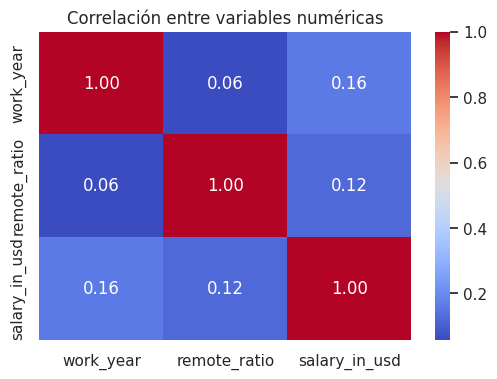

In [24]:
# Correlación entre las variables numéricas
plt.figure(figsize=(6, 4))
sns.heatmap(df_limpio[['work_year', 'remote_ratio', 'salary_in_usd']].corr(),
            annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlación entre variables numéricas')
plt.show()

**Interpretación:**

**Experiencia (el factor más fuerte).** El salario sube claramente con el nivel: la mediana pasa de **56.500 USD en Junior** a **76.940 en Semi-senior**, **135.000 en Senior** y **171.438 en Directivo**. Un senior gana unas **2,4 veces** lo que gana un junior. Los Directivos tienen además la mayor variación (desv. 117.071), aunque son solo 26 registros.

**Tamaño de la empresa.** Las empresas pequeñas pagan bastante menos (mediana **65.511 USD**) que las medianas (**109.640**) y las grandes (**100.000**). Entre mediana y grande la diferencia es pequeña, y la mediana incluso supera a la grande; la media sí es un poco mayor en las grandes (118.214 vs 114.807).

**Modalidad.** El trabajo remoto tiene la mayor mediana (**110.712 USD**), seguido del presencial (**98.158**). El híbrido es el más bajo (**68.010**), pero tiene pocos casos (98), por lo que conviene tomarlo con cuidado.

**Año.** La mediana sube de **75.544 en 2020** a **82.528 en 2021** y **120.000 en 2022**. Ojo: hay muchos más datos de 2022 (278) que de 2020 (72), y no sabemos si cambió el salario o el tipo de personas en la muestra.

**Tipo de empleo.** Casi todos son tiempo completo (546). Contrato, freelance y medio tiempo tienen muy pocos registros (4 a 10), así que no sacamos conclusiones de ellos.

**Correlaciones.** Las correlaciones con el salario son débiles: **0,16 con el año** y **0,12 con el porcentaje de trabajo remoto**. Esto no significa que el trabajo remoto no influya, sino que la relación lineal es pequeña por sí sola. Además, el mapa de calor solo incluye variables numéricas, y la experiencia (el factor más fuerte) es categórica, por eso no aparece. Recordemos que **correlación no significa causa**.

**Hipótesis:** la experiencia es el factor que más influye en el salario, más que el tamaño de la empresa o la modalidad. Lo comprobaremos con el modelo de la Etapa 3.

## 2.4 Valores atípicos (outliers)
Usamos la regla del rango intercuartílico (IQR): un salario es atípico si queda muy por encima o por debajo del resto.

In [25]:
q1 = sal.quantile(0.25)
q3 = sal.quantile(0.75)
iqr = q3 - q1
limite_inf = q1 - 1.5 * iqr
limite_sup = q3 + 1.5 * iqr

outliers = df_limpio[(sal < limite_inf) | (sal > limite_sup)]
print(f'Límite inferior: {limite_inf:,.0f} USD | Límite superior: {limite_sup:,.0f} USD')
print(f'Cantidad de outliers: {len(outliers)} ({len(outliers) / len(df_limpio) * 100:.1f}% de los datos)')
outliers.sort_values('salary_in_usd', ascending=False).head(10)

Límite inferior: -73,108 USD | Límite superior: 283,864 USD
Cantidad de outliers: 10 (1.8% de los datos)


,work_year,experience_level,employment_type,job_title,salary_in_usd,employee_residence,remote_ratio,company_location,company_size,modalidad
251,2021,Directivo,Tiempo completo,Principal Data Engineer,600000,US,100,US,Grande,Remoto
33,2020,Semi-senior,Tiempo completo,Research Scientist,450000,US,0,US,Mediana,Presencial
97,2021,Semi-senior,Tiempo completo,Financial Data Analyst,450000,US,100,US,Grande,Remoto
157,2021,Semi-senior,Tiempo completo,Applied Machine Learning Scientist,423000,US,50,US,Grande,Híbrido
224,2021,Directivo,Contrato,Principal Data Scientist,416000,US,100,US,Pequeña,Remoto
63,2020,Senior,Tiempo completo,Data Scientist,412000,US,100,US,Grande,Remoto
502,2022,Senior,Tiempo completo,Data Analytics Lead,405000,US,100,US,Grande,Remoto
498,2022,Senior,Tiempo completo,Applied Data Scientist,380000,US,100,US,Grande,Remoto
25,2020,Directivo,Tiempo completo,Director of Data Science,325000,US,100,US,Grande,Remoto
461,2022,Directivo,Tiempo completo,Data Engineer,324000,US,100,US,Mediana,Remoto


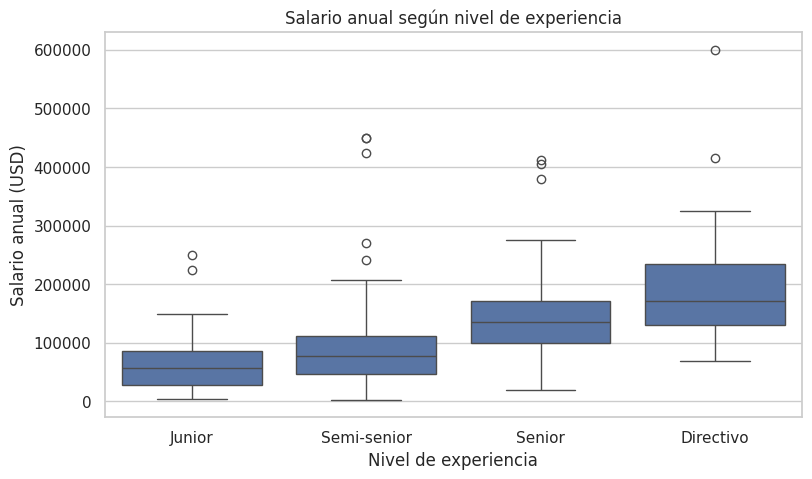

In [26]:
plt.figure(figsize=(9, 5))
sns.boxplot(data=df_limpio, x='experience_level', y='salary_in_usd', order=orden_exp)
plt.title('Salario anual según nivel de experiencia')
plt.xlabel('Nivel de experiencia')
plt.ylabel('Salario anual (USD)')
plt.show()

**Interpretación:** Con la regla del IQR, un salario es atípico si supera **283.864 USD** (el límite inferior es negativo, así que no hay valores atípicos por abajo). Encontramos **10 outliers, el 1,8% de los datos**, todos por encima del límite superior.

Lo que tienen en común los 10 casos:
- **Todos son de Estados Unidos**, tanto la residencia de la persona como la ubicación de la empresa.
- Son cargos de alto nivel o muy especializados: *Principal Data Engineer*, *Research Scientist*, *Applied Machine Learning Scientist*, *Director of Data Science*, entre otros.
- Casi todos son **tiempo completo** y trabajan en empresas **grandes** (7 de 10).
- **8 de 10 son 100% remotos**, y se reparten en los tres años.
- Por experiencia: 4 directivos, 3 seniors y 3 semi-seniors.

**Decisión:** **los dejamos en el análisis.** No parecen errores de digitación: los cargos y los montos son coherentes con salarios altos reales en Estados Unidos. Eliminarlos haría que el análisis ignore la parte alta del mercado. Sí tenemos presente que **suben el promedio** (por eso usamos la mediana) y pueden afectar el modelo de regresión.

**Lectura del boxplot:** el salario aumenta con la experiencia, y las cajas de Senior y Directivo están claramente por encima de las de Junior y Semi-senior. En cada grupo aparecen algunos puntos atípicos arriba (por ejemplo, un directivo con 600.000 USD y varios semi-seniors con más de 400.000). Los Directivos tienen la caja más ancha, es decir, la mayor variación entre sus salarios.

**Hipótesis:** creemos que **la experiencia es el factor que más influye en el salario**, más que el tamaño de la empresa o la modalidad de trabajo, porque las diferencias entre niveles (mediana de 56.500 USD en Junior frente a 135.000 en Senior) son mucho mayores que las diferencias entre modalidades o tamaños de empresa. Además, creemos que el país (Estados Unidos) también influye mucho, como sugieren los outliers. Lo comprobaremos con los gráficos y el modelo de la Etapa 3.

---
# ETAPA 3: Visualizaciones, storytelling y modelo

## 3.1 Visualizaciones clave
Cada gráfico responde una parte de la historia.

In [ ]:
# 1) ¿Cómo se distribuyen los salarios?
plt.figure(figsize=(9, 5))
sns.histplot(sal, bins=30, kde=True, color='steelblue')
plt.axvline(sal.mean(), color='red', linestyle='--', label=f'Media: {sal.mean():,.0f}')
plt.axvline(sal.median(), color='green', linestyle='--', label=f'Mediana: {sal.median():,.0f}')
plt.title('Distribución del salario anual en ciencia de datos')
plt.xlabel('Salario anual (USD)')
plt.ylabel('Cantidad de personas')
plt.legend()
plt.show()

In [ ]:
# 2) ¿Cuánto influye la experiencia?
plt.figure(figsize=(8, 5))
mediana_exp = df_limpio.groupby('experience_level', observed=True)['salary_in_usd'].median()
ax = mediana_exp.plot(kind='bar', color='steelblue')
ax.bar_label(ax.containers[0], fmt='{:,.0f}')
plt.title('Salario mediano según nivel de experiencia')
plt.xlabel('Nivel de experiencia')
plt.ylabel('Salario mediano (USD)')
plt.xticks(rotation=0)
plt.show()

In [ ]:
# 3) ¿Importa el tamaño de la empresa y la modalidad?
fig, ejes = plt.subplots(1, 2, figsize=(13, 5))

sns.boxplot(data=df_limpio, x='company_size', y='salary_in_usd',
            order=['Pequeña', 'Mediana', 'Grande'], ax=ejes[0])
ejes[0].set_title('Salario según tamaño de la empresa')
ejes[0].set_xlabel('Tamaño de la empresa')
ejes[0].set_ylabel('Salario anual (USD)')

sns.boxplot(data=df_limpio, x='modalidad', y='salary_in_usd',
            order=['Presencial', 'Híbrido', 'Remoto'], ax=ejes[1])
ejes[1].set_title('Salario según modalidad de trabajo')
ejes[1].set_xlabel('Modalidad')
ejes[1].set_ylabel('Salario anual (USD)')

plt.tight_layout()
plt.show()

In [ ]:
# 4) ¿Qué cargos son más comunes y cuánto pagan?
top_cargos = df_limpio['job_title'].value_counts().head(10).index
datos_cargos = df_limpio[df_limpio['job_title'].isin(top_cargos)]
mediana_cargos = datos_cargos.groupby('job_title')['salary_in_usd'].median().sort_values()

plt.figure(figsize=(9, 6))
mediana_cargos.plot(kind='barh', color='steelblue')
plt.title('Salario mediano de los 10 cargos más frecuentes')
plt.xlabel('Salario mediano (USD)')
plt.ylabel('Cargo')
plt.show()

In [ ]:
# 5) ¿Cómo cambió el salario entre 2020 y 2022?
plt.figure(figsize=(7, 5))
por_anio = df_limpio.groupby('work_year')['salary_in_usd'].median()
plt.plot(por_anio.index, por_anio.values, marker='o', color='steelblue')
plt.xticks([2020, 2021, 2022])
plt.title('Salario mediano por año')
plt.xlabel('Año')
plt.ylabel('Salario mediano (USD)')
plt.show()

In [ ]:
# 6) ¿En qué países pagan más? (solo países con al menos 5 registros)
por_pais = df_limpio.groupby('company_location')['salary_in_usd'].agg(['count', 'median'])
por_pais = por_pais[por_pais['count'] >= 5].sort_values('median', ascending=False).head(10)

plt.figure(figsize=(9, 5))
por_pais['median'].sort_values().plot(kind='barh', color='steelblue')
plt.title('Top 10 países por salario mediano (código de país de la empresa)')
plt.xlabel('Salario mediano (USD)')
plt.ylabel('País')
plt.show()

## 3.2 Storytelling: lo que cuentan los datos
(Escriban la historia en 4 o 5 frases siguiendo el esquema **dato → gráfico → conclusión**. Ejemplo de estructura:)

1. **Punto de partida:** El salario típico en ciencia de datos es de ___ USD al año, pero varía muchísimo.
2. **Qué lo explica:** La experiencia es lo que más pesa: un senior gana ___ veces lo que gana un junior.
3. **Qué influye menos o más de lo esperado:** El tamaño de la empresa / el trabajo remoto ___.
4. **Tendencia en el tiempo:** Entre 2020 y 2022 el salario mediano ___.
5. **Mensaje final:** ___

## 3.3 Modelo predictivo: regresión lineal
**Objetivo:** predecir el salario anual en USD a partir de la experiencia, el tamaño de la empresa, la modalidad remota y el año.

Como la mayoría de los registros son de tiempo completo, usamos solo esos para que el modelo compare cosas parecidas. Las variables de texto se convierten a columnas de 0 y 1 (esto se llama *one-hot encoding*).

In [ ]:
# Solo empleos de tiempo completo
df_modelo = df_limpio[df_limpio['employment_type'] == 'Tiempo completo'].copy()
print('Registros usados en el modelo:', len(df_modelo))

# Variables predictoras (X) y variable a predecir (y)
X = pd.get_dummies(
    df_modelo[['experience_level', 'company_size', 'work_year', 'remote_ratio']],
    drop_first=True, dtype=int)
y = df_modelo['salary_in_usd']

# 80% para entrenar, 20% para probar
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

modelo = LinearRegression()
modelo.fit(X_train, y_train)
y_pred = modelo.predict(X_test)

X.head()

In [ ]:
# Evaluación del modelo con los datos de prueba
r2 = r2_score(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))

print(f'R²: {r2:.3f}  (el modelo explica el {r2 * 100:.1f}% de la variación del salario)')
print(f'Error absoluto medio (MAE): {mae:,.0f} USD')
print(f'Raíz del error cuadrático medio (RMSE): {rmse:,.0f} USD')

In [ ]:
# Valores reales vs predichos
plt.figure(figsize=(7, 6))
plt.scatter(y_test, y_pred, alpha=0.5, color='steelblue')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', label='Predicción perfecta')
plt.xlabel('Salario real (USD)')
plt.ylabel('Salario predicho (USD)')
plt.title('Modelo de regresión lineal: real vs predicho')
plt.legend()
plt.show()

In [ ]:
# ¿Qué variables pesan más? Cada coeficiente es el cambio en USD frente al grupo de referencia
# (referencia: nivel Junior, empresa Grande; work_year y remote_ratio son numéricas)
coeficientes = pd.Series(modelo.coef_, index=X.columns).sort_values()
print(coeficientes.round(0))

plt.figure(figsize=(8, 5))
coeficientes.plot(kind='barh', color='steelblue')
plt.title('Peso de cada variable en el salario predicho')
plt.xlabel('Efecto en el salario (USD)')
plt.show()

In [ ]:
# Ejemplo de predicción: profesional Senior, empresa Grande, 100% remoto, año 2022
ejemplo = pd.DataFrame(0, index=[0], columns=X.columns)
ejemplo['work_year'] = 2022
ejemplo['remote_ratio'] = 100
ejemplo['experience_level_Senior'] = 1

print(f'Salario estimado: {modelo.predict(ejemplo)[0]:,.0f} USD al año')

**Interpretación del modelo:**
- **Qué hace:** predice el salario anual a partir de experiencia, tamaño de empresa, modalidad y año.
- **Qué tan bien funciona:** (R² de ___ significa que explica ___% de la variación; el error típico es de ___ USD).
- **Qué variables influyen más:** (según los coeficientes, por ejemplo: ser Senior suma ___ USD frente a un Junior).
- **Limitaciones:** (el modelo no conoce el cargo exacto ni el país, que también influyen mucho; hay pocos datos de algunos grupos; los salarios muy altos son difíciles de predecir).
- **Cómo mejorarlo:** (agregar país, cargo, o probar otros modelos).

---
# CONCLUSIONES

## Hallazgos principales
1. (hallazgo 1, con un número)
2. (hallazgo 2, con un número)
3. (hallazgo 3, con un número)

## Aplicación profesional
(Sean concretos. Ideas: usar este análisis como referencia salarial para negociar un empleo; ayudar a un área de recursos humanos a definir rangos de pago por nivel de experiencia; decidir qué habilidades o nivel de experiencia buscar para crecer profesionalmente; comparar ofertas remotas vs presenciales.)

## Qué aprendimos
(Reflexión del equipo: qué fue lo más difícil, qué herramientas aprendieron a usar y cómo las aplicarían.)